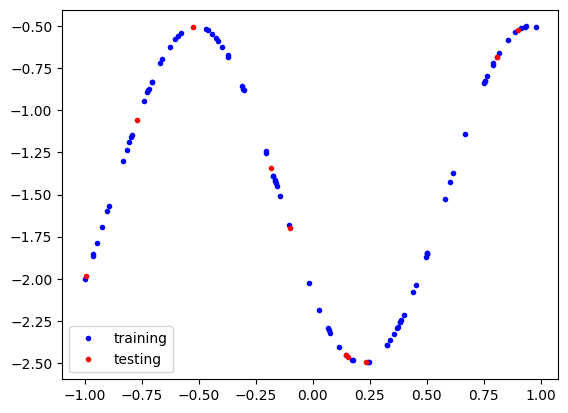

In [ ]:
#@title Prepare a simulated dataset

import numpy as np
import torch
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.lines import Line2D
import torch.nn.functional as F
# %matplotlib inline

# number of data points,
num_data = 100
train_data_ratio = 0.9
train_num = int(num_data * train_data_ratio)

# generate data
np.random.seed(1)
x_np = np.random.uniform(-1, 1, size=(num_data, 1))  # 1-dim data

# ground truth curve
t = 2.2
w = 4.3
b = -1.5

# use torch for target to match later ops
x_all = torch.from_numpy(x_np).float()
y_all = torch.cos(w * x_all + t) + b

# data split
train_x = x_all[:train_num, :]
train_y = y_all[:train_num, :]
test_x  = x_all[train_num:, :]
test_y  = y_all[train_num:, :]

data = dict([('train_x', train_x), ('train_y', train_y),
             ('test_x', test_x),   ('test_y', test_y)])

plt.plot(data['train_x'].numpy(), data['train_y'].numpy(), '.b', label='training')
plt.plot(data['test_x'].numpy(),  data['test_y'].numpy(),  '.r', label='testing')
plt.legend()
plt.show()

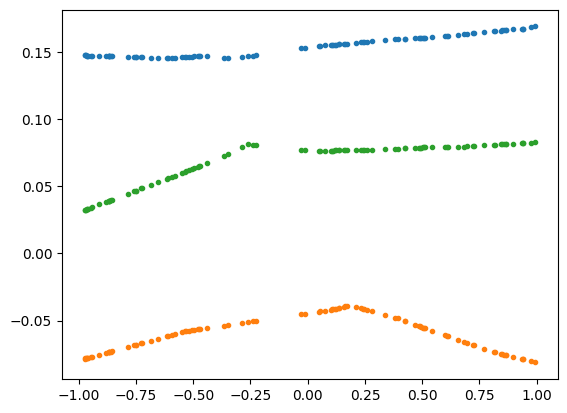

In [ ]:
#@title Hand build a simple MLP

def relu(x):
    ''' Activation Function '''
    return x * (x > 0)

def mlp(params, x):
    '''
    MLP that supports an arbitrary number of layers

    params is a list of (weights, bias) tuples.
    ReLU is applied after every layer except the final layer.


    '''
    h = x

    for i, (w, b) in enumerate(params):
        h = h @ w.t() + b

        #Apply ReLU to every layer except the output layer
        if i < len(params) - 1:
            h = relu(h)
    return h


def initialize_params(sizes, scale=1e-1, seed=1):
    ''' Initialize the weights of all layers of a linear layer network '''
    '''sizes=[input_dim, hidden_dim, output_dim]'''
    g = torch.Generator(device='cpu')
    g.manual_seed(seed)

    def initialize_layer(m, n, g, scale):
        w = scale * torch.randn(n, m, generator=g)
        b = scale * torch.randn(n,     generator=g)
        # requires_grad will be set during training
        return (w, b)

    return [initialize_layer(m, n, g, scale) for m, n in zip(sizes[:-1], sizes[1:])]

# input_dim, hidden_dim, output_dim
layer_sizes = [1, 50, 1]
# Return a list of tuples of layer weights
params_rnd = initialize_params(layer_sizes, seed=1, scale=1e-1)

# plot some neural networks with random weights.
x_plot = torch.from_numpy(np.random.uniform(-1, 1, size=(100, 1))).float()  # 1-dim data
ypred = mlp(params_rnd, x_plot).detach().numpy()
plt.plot(x_plot.numpy(), ypred, '.')
ypred = mlp(initialize_params(layer_sizes, seed=10), x_plot).detach().numpy()
plt.plot(x_plot.numpy(), ypred, '.')
ypred = mlp(initialize_params(layer_sizes, seed=100), x_plot).detach().numpy()
plt.plot(x_plot.numpy(), ypred, '.')
plt.show()


In [ ]:
#@title Gradient descent

def mse_loss(params, x, y):
    ''' Define the loss function with MSE loss '''
    pred = mlp(params, x)
    return torch.mean((pred - y) ** 2)

#  One step of gradient descent
def gd_step(params, loss_fun, x, y, step_size = 1e-1):
    ''' Calculate gradient and update the parameters '''
    # enable grads
    params_rg = []
    for (w, b) in params:
        w = w.detach().clone().requires_grad_(True)
        b = b.detach().clone().requires_grad_(True)
        params_rg.append((w, b))

    loss = loss_fun(params_rg, x, y)
    loss.backward()

    params_new = []
    for (w, b) in params_rg:
        w_new = (w - step_size * w.grad).detach()
        b_new = (b - step_size * b.grad).detach()
        params_new.append((w_new, b_new))

    return params_new, loss.detach()

# Gradient descent main algorithm
def gd_train(params_initial, loss_fun, model, data, step_size=1e-1, steps=200):
    # initialization
    params = [(w.detach(), b.detach()) for (w, b) in params_initial]
    Losses_train = []
    Losses_test = []
    Pred = []

    # main loop
    for i in range(steps):
        params, loss_train = gd_step(params, loss_fun, data['train_x'], data['train_y'], step_size=step_size)
        with torch.no_grad():
            loss_test = loss_fun(params, data['test_x'], data['test_y'])

        Losses_train.append(loss_train.item())
        Losses_test.append(loss_test.item())
        with torch.no_grad():
            Pred.append(model(params, data['train_x']).detach().clone())
        if i % 100 == 0:
            print('Step {} | Training Loss:{:.2f} | Testing Loss:{:.2f}'.format(i, Losses_train[-1], Losses_test[-1]))

    trajectory = dict([('training_loss', Losses_train),
                       ('testing_loss',  Losses_test),
                       ('train_y_pred',  Pred)])
    return params, trajectory

Step 0 | Training Loss:2.81 | Testing Loss:2.08
Step 100 | Training Loss:0.40 | Testing Loss:0.55
Step 200 | Training Loss:0.24 | Testing Loss:0.34
Step 300 | Training Loss:0.16 | Testing Loss:0.23
Step 400 | Training Loss:0.11 | Testing Loss:0.17
Step 500 | Training Loss:0.07 | Testing Loss:0.10
Step 600 | Training Loss:0.04 | Testing Loss:0.05
Step 700 | Training Loss:0.02 | Testing Loss:0.03
Step 800 | Training Loss:0.01 | Testing Loss:0.02
Step 900 | Training Loss:0.01 | Testing Loss:0.01


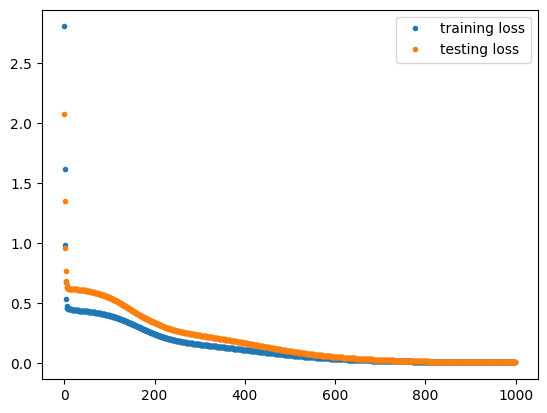

In [ ]:
#@title Main training loop

params_initial = initialize_params(layer_sizes, seed=1, scale=1e-1)
loss_fun = mse_loss
model = mlp
params, trajectory = gd_train(params_initial, loss_fun, model, data, step_size=1e-1, steps=1000)

plt.plot(trajectory['training_loss'], '.', label='training loss')
plt.plot(trajectory['testing_loss'],  '.', label='testing loss')
plt.legend()
plt.show()


In [ ]:
# Visualize the fitting process
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np
import matplotlib.pyplot as plt

def show_cartoon(data, trajectory):
    # cache numpy arrays once (avoid repeated .numpy() calls)
    tx = data['train_x'].detach().cpu().numpy()
    ty = data['train_y'].detach().cpu().numpy()
    preds = [p.detach().cpu().numpy() for p in trajectory['train_y_pred']]

    step = 10
    n_frames = max(1, min(len(preds) // step, 100))
    fig, ax = plt.subplots()
    sc_truth = ax.scatter(tx, ty, color='b', s=10, label='Ground Truth')
    sc_pred = ax.scatter(tx, preds[0], color='r', s=10, label='Training Prediction')

    ax.set_xlim(-1, 1)
    ax.set_ylim(-3, 0)
    ax.legend(loc='upper right')

    def animate(frame_num):
        idx = frame_num * step
        sc_pred.set_offsets(np.c_[tx, preds[idx].reshape(-1)])
        return (sc_pred,)

    anim = FuncAnimation(fig, animate, frames=n_frames, interval=60, blit=False)
    return fig, anim

fig, anim = show_cartoon(data, trajectory)

html = HTML(anim.to_jshtml())
plt.close(fig)
html


# Try networks of different sizes, both depth and width


In [ ]:
#What happens when I add more hidden layers?

depth_architectures = [
    [1, 50, 1],
    [1, 50, 50, 1],
    [1, 50, 50, 50, 1]
]

In [ ]:
depth_results = {}

for architecture in depth_architectures:
    print("Training:", architecture)

    params_initial = initialize_params(
        architecture,
        seed=1,
        scale=1e-1
    )

    params, trajectory = gd_train(
        params_initial,
        mse_loss,
        mlp,
        data,
        step_size=1e-1,
        steps=1000
    )

    depth_results[str(architecture)] = {
        "params": params,
        "trajectory": trajectory
    }

Training: [1, 50, 1]
Step 0 | Training Loss:2.81 | Testing Loss:2.08
Step 100 | Training Loss:0.40 | Testing Loss:0.55
Step 200 | Training Loss:0.24 | Testing Loss:0.34
Step 300 | Training Loss:0.16 | Testing Loss:0.23
Step 400 | Training Loss:0.11 | Testing Loss:0.17
Step 500 | Training Loss:0.07 | Testing Loss:0.10
Step 600 | Training Loss:0.04 | Testing Loss:0.05
Step 700 | Training Loss:0.02 | Testing Loss:0.03
Step 800 | Training Loss:0.01 | Testing Loss:0.02
Step 900 | Training Loss:0.01 | Testing Loss:0.01
Training: [1, 50, 50, 1]
Step 0 | Training Loss:2.39 | Testing Loss:1.57
Step 100 | Training Loss:0.32 | Testing Loss:0.44
Step 200 | Training Loss:0.09 | Testing Loss:0.13
Step 300 | Training Loss:0.10 | Testing Loss:0.08
Step 400 | Training Loss:0.02 | Testing Loss:0.02
Step 500 | Training Loss:0.01 | Testing Loss:0.01
Step 600 | Training Loss:0.01 | Testing Loss:0.01
Step 700 | Training Loss:0.00 | Testing Loss:0.00
Step 800 | Training Loss:0.00 | Testing Loss:0.00
Step 900

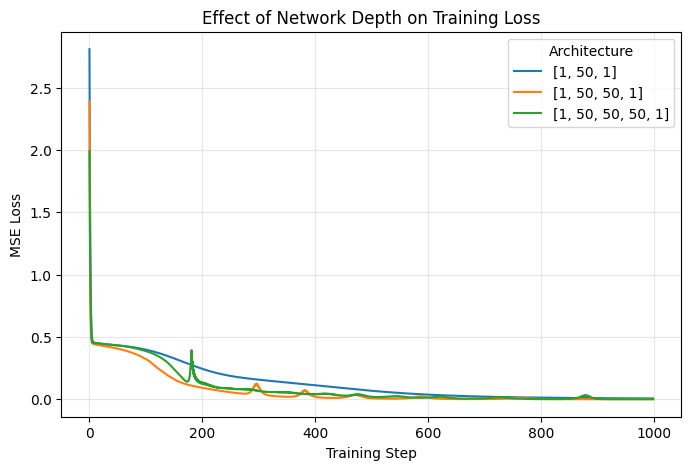

In [ ]:
plt.figure(figsize=(8, 5))

for architecture, result in depth_results.items():
    plt.plot(
        result["trajectory"]["training_loss"],
        label=architecture
    )

plt.xlabel("Training Step")
plt.ylabel("MSE Loss")
plt.title("Effect of Network Depth on Training Loss")
plt.legend(title="Architecture")
plt.grid(alpha=0.3)
plt.show()

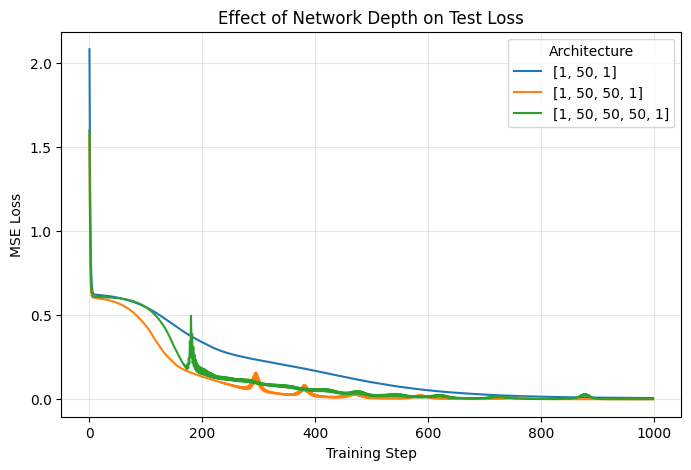

In [ ]:
plt.figure(figsize=(8, 5))

for architecture, result in depth_results.items():
    plt.plot(
        result["trajectory"]["testing_loss"],
        label=architecture
    )

plt.xlabel("Training Step")
plt.ylabel("MSE Loss")
plt.title("Effect of Network Depth on Test Loss")
plt.legend(title="Architecture")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
#What happens when I add more neurons?
width_architectures = [
    [1, 10, 1],
    [1, 50, 1],
    [1, 100, 1]
]

In [ ]:
# Different widths
width_results = {}

for architecture in width_architectures:
    print("Training:", architecture)

    params_initial = initialize_params(
        architecture,
        seed=1,
        scale=1e-1
    )

    params, trajectory = gd_train(
        params_initial,
        mse_loss,
        mlp,
        data,
        step_size=1e-1,
        steps=1000
    )

    width_results[str(architecture)] = {
        "params": params,
        "trajectory": trajectory
    }

Training: [1, 10, 1]
Step 0 | Training Loss:2.12 | Testing Loss:1.96
Step 100 | Training Loss:0.44 | Testing Loss:0.62
Step 200 | Training Loss:0.41 | Testing Loss:0.59
Step 300 | Training Loss:0.37 | Testing Loss:0.52
Step 400 | Training Loss:0.32 | Testing Loss:0.43
Step 500 | Training Loss:0.26 | Testing Loss:0.36
Step 600 | Training Loss:0.22 | Testing Loss:0.31
Step 700 | Training Loss:0.21 | Testing Loss:0.31
Step 800 | Training Loss:0.22 | Testing Loss:0.38
Step 900 | Training Loss:0.44 | Testing Loss:0.72
Training: [1, 50, 1]
Step 0 | Training Loss:2.81 | Testing Loss:2.08
Step 100 | Training Loss:0.40 | Testing Loss:0.55
Step 200 | Training Loss:0.24 | Testing Loss:0.34
Step 300 | Training Loss:0.16 | Testing Loss:0.23
Step 400 | Training Loss:0.11 | Testing Loss:0.17
Step 500 | Training Loss:0.07 | Testing Loss:0.10
Step 600 | Training Loss:0.04 | Testing Loss:0.05
Step 700 | Training Loss:0.02 | Testing Loss:0.03
Step 800 | Training Loss:0.01 | Testing Loss:0.02
Step 900 | T

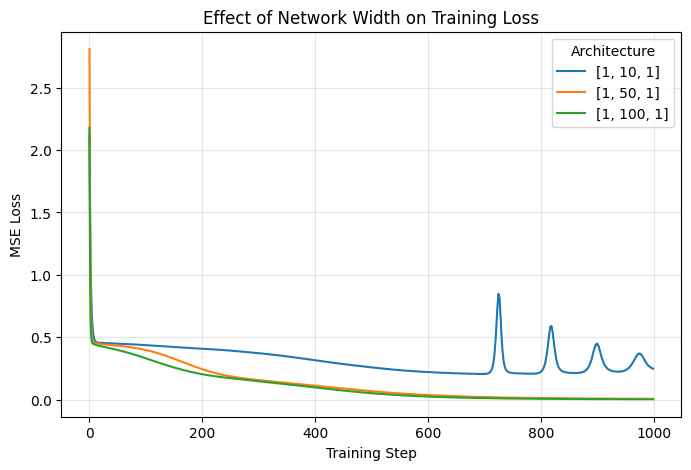

In [ ]:
plt.figure(figsize=(8, 5))

for architecture, result in width_results.items():
    plt.plot(
        result["trajectory"]["training_loss"],
        label=architecture
    )

plt.xlabel("Training Step")
plt.ylabel("MSE Loss")
plt.title("Effect of Network Width on Training Loss")
plt.legend(title="Architecture")
plt.grid(alpha=0.3)
plt.show()

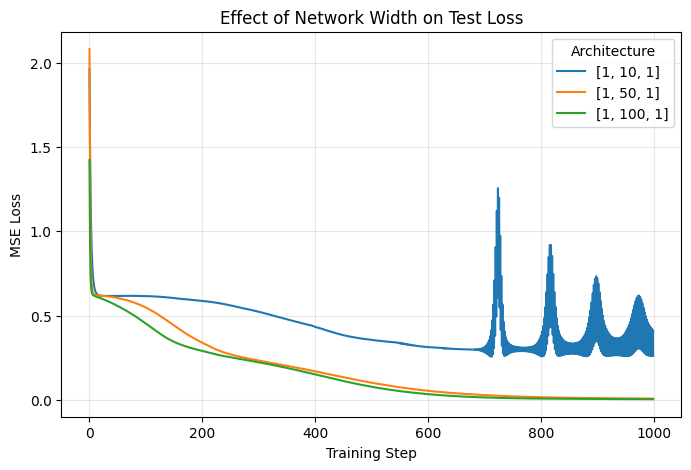

In [ ]:
plt.figure(figsize=(8, 5))

for architecture, result in width_results.items():
    plt.plot(
        result["trajectory"]["testing_loss"],
        label=architecture
    )

plt.xlabel("Training Step")
plt.ylabel("MSE Loss")
plt.title("Effect of Network Width on Test Loss")
plt.legend(title="Architecture")
plt.grid(alpha=0.3)
plt.show()

### Architectures I tested

To study network depth, I tested [1, 50, 1], [1, 50, 50, 1], and [1, 50, 50, 50, 1]. These architectures have one, two, and three hidden layers, respectively, while keeping the width of each hidden layer at 50 neurons.

To study network width, I tested [1, 10, 1], [1, 50, 1], and [1, 100, 1]. These architectures all have one hidden layer, while the number of hidden neurons increases from 10 to 50 to 100.



### Effect of depth

Increasing network depth generally caused the training and test losses to decrease faster. The two-hidden-layer network [1, 50, 50, 1] reached low training and test loss much sooner than the one-hidden-layer network [1, 50, 1]. The three-hidden-layer network [1, 50, 50, 50, 1] also reached near-zero loss, although its loss showed some fluctuations during training. By the end of training, all three depth configurations achieved very low training and test loss.

### Effect of width

Increasing network width had a clear effect on performance. The network with only 10 hidden neurons had substantially higher training and test loss and showed several fluctuations later in training. In contrast, the networks with 50 and 100 hidden neurons reached nearly zero training and test loss. The 100-neuron network generally converged faster than the 50-neuron network. Overall, increasing width improved performance on this dataset.

# Try different values of sigma, for example 10^-5, 10^-1, and 10.

In [ ]:
scale_values = [
    1e-5,
    1e-2,
    5e-2,
    1e-1,
    10
]

In [ ]:
architecture = [1, 50, 50, 50, 1]

In [ ]:
scale_results = {}

for scale in scale_values:
    print("Training with scale:", scale)

    params_initial = initialize_params(
        architecture,
        seed=1,
        scale=scale
    )

    params, trajectory = gd_train(
        params_initial,
        mse_loss,
        mlp,
        data,
        step_size=1e-1,
        steps=1000
    )

    scale_results[scale] = {
        "params": params,
        "trajectory": trajectory
    }

    print()

Training with scale: 1e-05
Step 0 | Training Loss:2.36 | Testing Loss:2.14
Step 100 | Training Loss:0.46 | Testing Loss:0.61
Step 200 | Training Loss:0.46 | Testing Loss:0.61
Step 300 | Training Loss:0.46 | Testing Loss:0.61
Step 400 | Training Loss:0.46 | Testing Loss:0.61
Step 500 | Training Loss:0.46 | Testing Loss:0.61
Step 600 | Training Loss:0.46 | Testing Loss:0.61
Step 700 | Training Loss:0.46 | Testing Loss:0.61
Step 800 | Training Loss:0.46 | Testing Loss:0.61
Step 900 | Training Loss:0.46 | Testing Loss:0.61

Training with scale: 0.01
Step 0 | Training Loss:2.33 | Testing Loss:2.12
Step 100 | Training Loss:0.46 | Testing Loss:0.61
Step 200 | Training Loss:0.46 | Testing Loss:0.61
Step 300 | Training Loss:0.46 | Testing Loss:0.61
Step 400 | Training Loss:0.46 | Testing Loss:0.61
Step 500 | Training Loss:0.46 | Testing Loss:0.61
Step 600 | Training Loss:0.46 | Testing Loss:0.61
Step 700 | Training Loss:0.46 | Testing Loss:0.61
Step 800 | Training Loss:0.46 | Testing Loss:0.61


In [ ]:
# Consistent colors
sigma_colors = {
    1e-5: "tab:blue",
    1e-2: "tab:orange",
    5e-2: "tab:green",
    1e-1: "tab:red",
    10.0: "tab:purple"
}

# Different line styles help when curves overlap
sigma_styles = {
    1e-5: "-",
    1e-2: "--",
    5e-2: "-.",
    1e-1: "-",
    10.0: ":"
}

# Cleaner labels
sigma_labels = {
    1e-5: r"$\sigma=10^{-5}$",
    1e-2: r"$\sigma=10^{-2}$",
    5e-2: r"$\sigma=5\times10^{-2}$",
    1e-1: r"$\sigma=10^{-1}$",
    10.0: r"$\sigma=10$"
}

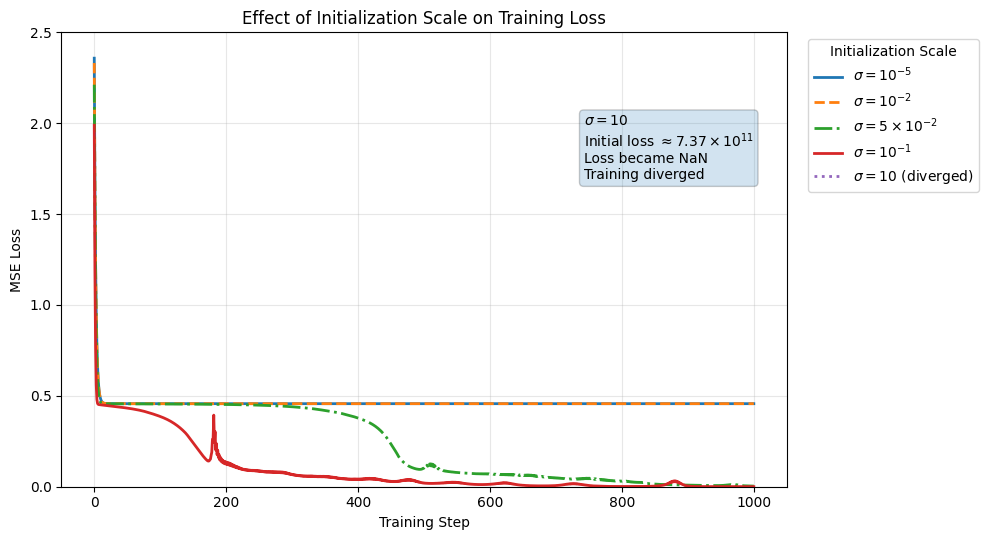

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))

for scale in scale_values:

    if scale == 10.0:
        continue

    losses = scale_results[scale]["trajectory"]["training_loss"]

    ax.plot(
        losses,
        label=sigma_labels[scale],
        color=sigma_colors[scale],
        linestyle=sigma_styles[scale],
        linewidth=2
    )

ax.set_xlabel("Training Step")
ax.set_ylabel("MSE Loss")
ax.set_title("Effect of Initialization Scale on Training Loss")

ax.set_ylim(0, 2.5)
ax.grid(alpha=0.3)

handles, labels = ax.get_legend_handles_labels()

handles.append(
    Line2D(
        [0],
        [0],
        color="tab:purple",
        linestyle=":",
        linewidth=2,
        label=r"$\sigma=10$ (diverged)"
    )
)

ax.legend(
    handles=handles,
    title="Initialization Scale",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
# Explain what happened to sigma = 10
ax.text(
    0.72,
    0.82,
    r"$\sigma = 10$" + "\n"
    r"Initial loss $\approx 7.37\times10^{11}$" + "\n"
    "Loss became NaN\n"
    "Training diverged",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        alpha=0.2
    )
)

plt.tight_layout()
plt.show()

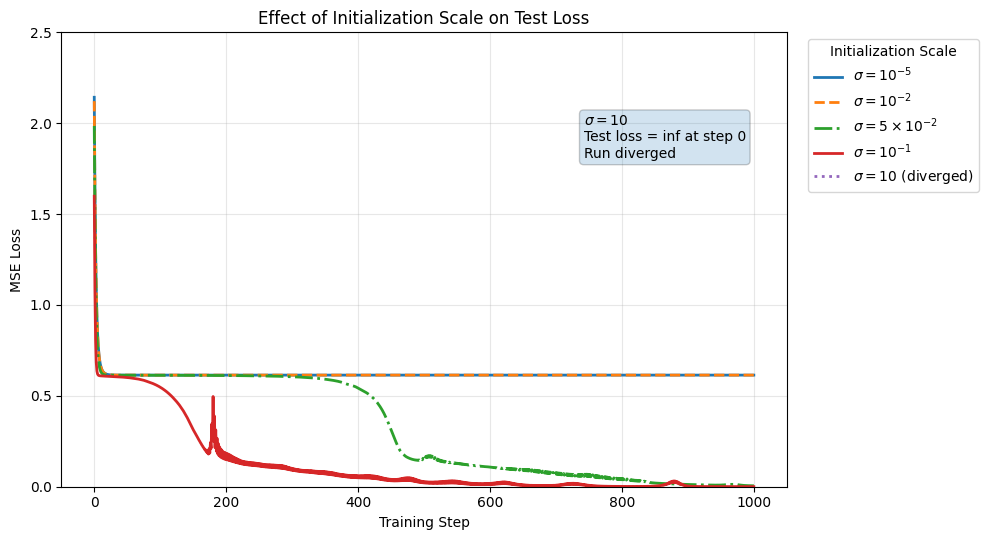

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))

for scale in scale_values:

    if scale == 10.0:
        continue

    losses = scale_results[scale]["trajectory"]["testing_loss"]

    ax.plot(
        losses,
        label=sigma_labels[scale],
        color=sigma_colors[scale],
        linestyle=sigma_styles[scale],
        linewidth=2
    )

ax.set_xlabel("Training Step")
ax.set_ylabel("MSE Loss")
ax.set_title("Effect of Initialization Scale on Test Loss")

ax.set_ylim(0, 2.5)
ax.grid(alpha=0.3)

handles, labels = ax.get_legend_handles_labels()

handles.append(
    Line2D(
        [0],
        [0],
        color="tab:purple",
        linestyle=":",
        linewidth=2,
        label=r"$\sigma=10$ (diverged)"
    )
)

ax.legend(
    handles=handles,
    title="Initialization Scale",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

# Show what happened to sigma = 10
ax.text(
    0.72,
    0.82,
    r"$\sigma = 10$" + "\n"
    "Test loss = inf at step 0\n"
    "Run diverged",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        alpha=0.2
    )
)

plt.tight_layout()
plt.show()

### Effect of Initialization Scale

Based on my experiments and observations, I found that the initialization scale,  𝜎 , had a large effect on how well the network trained.

When $\sigma$ is too small, such as $10^{-5}$ and $10^{-2}$, the weights start very close to zero. This makes the signals passed through the network very small. Small initialization values can cause the activations and gradients to become very small. In a deep network, these gradients may become even smaller as they propagate backward, which can lead to the vanishing gradient problem and cause earlier layers to learn very slowly or stop improving.

This behavior was visible in my experiment. For $\sigma = 10^{-5}$ and $\sigma = 10^{-2}$, the loss decreased at first but then stopped improving. The training loss remained around $0.46$, while the test loss remained around $0.61$. In comparison, moderate values such as $\sigma = 0.05$ and $\sigma = 0.1$ were able to continue reducing the loss.



For $\sigma = 10$, my experiment showed:

*   Training loss $\approx 7.37 \times 10^{11}$ at step 0
*   Test loss = inf at step 0
*   Later losses became NaN

When $\sigma$ is too large, the weights can produce very large activations and gradients. These values can grow as they pass through the layers, causing exploding gradients and unstable training. In my experiment, $\sigma = 10$ caused the loss to become inf and NaN, showing that the training had diverged.

An initialization strategy that can help is He initialization, also called Kaiming initialization. My network uses ReLU activations, and He initialization is designed for networks that use ReLU. Instead of using one arbitrary fixed scale for every layer, it chooses the weight scale based on the number of inputs to each layer:

$$
\sigma = \sqrt{\frac{2}{\text{fan\_in}}}
$$

This helps keep the activations and gradients at more reasonable magnitudes as they move through the network, reducing the risk of vanishing or exploding gradients.

# Replace ReLU activation with Sigmoid and repeat training

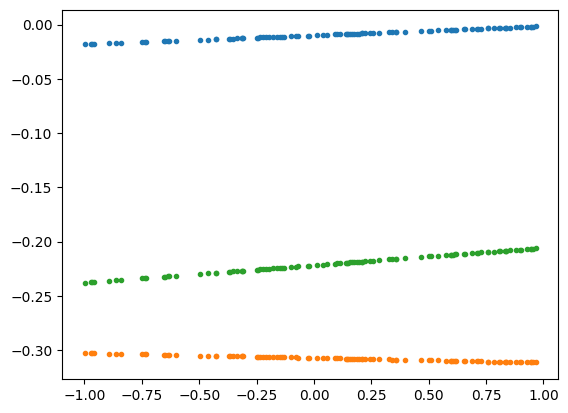

In [ ]:
#@title Hand build a Sigmoid MLP

def sigmoid(x):
    return torch.sigmoid(x)


def mlp_sigmoid(params, x):
    """
    MLP using Sigmoid after every hidden layer.
    The final output layer stays linear.
    """
    h = x

    for i, (w, b) in enumerate(params):
        h = h @ w.t() + b

        # Sigmoid on hidden layers only
        if i < len(params) - 1:
            h = sigmoid(h)

    return h


def initialize_params(sizes, scale=1e-1, seed=1):
    ''' Initialize the weights of all layers of a linear layer network '''
    '''sizes=[input_dim, hidden_dim, output_dim]'''
    g = torch.Generator(device='cpu')
    g.manual_seed(seed)

    def initialize_layer(m, n, g, scale):
        w = scale * torch.randn(n, m, generator=g)
        b = scale * torch.randn(n,     generator=g)
        # requires_grad will be set during training
        return (w, b)

    return [initialize_layer(m, n, g, scale) for m, n in zip(sizes[:-1], sizes[1:])]

# input_dim, hidden_dim, output_dim
layer_sizes = [1, 50, 1]
# Return a list of tuples of layer weights
params_rnd = initialize_params(layer_sizes, seed=1, scale=1e-1)

# plot some neural networks with random weights.
x_plot = torch.from_numpy(np.random.uniform(-1, 1, size=(100, 1))).float()  # 1-dim data
ypred = mlp_sigmoid(params_rnd, x_plot).detach().numpy()
plt.plot(x_plot.numpy(), ypred, '.')
ypred = mlp_sigmoid(initialize_params(layer_sizes, seed=10), x_plot).detach().numpy()
plt.plot(x_plot.numpy(), ypred, '.')
ypred = mlp_sigmoid(initialize_params(layer_sizes, seed=100), x_plot).detach().numpy()
plt.plot(x_plot.numpy(), ypred, '.')
plt.show()

In [ ]:
#@title Gradient descent

def sigmoid_mse_loss(params, x, y):
    pred = mlp_sigmoid(params, x)
    return torch.mean((pred - y) ** 2)

#  One step of gradient descent
def gd_step(params, loss_fun, x, y, step_size = 1e-1):
    ''' Calculate gradient and update the parameters '''
    # enable grads
    params_rg = []
    for (w, b) in params:
        w = w.detach().clone().requires_grad_(True)
        b = b.detach().clone().requires_grad_(True)
        params_rg.append((w, b))

    loss = loss_fun(params_rg, x, y)
    loss.backward()

    params_new = []
    for (w, b) in params_rg:
        w_new = (w - step_size * w.grad).detach()
        b_new = (b - step_size * b.grad).detach()
        params_new.append((w_new, b_new))

    return params_new, loss.detach()

# Gradient descent main algorithm
def gd_train(params_initial, loss_fun, model, data, step_size=1e-1, steps=200):
    # initialization
    params = [(w.detach(), b.detach()) for (w, b) in params_initial]
    Losses_train = []
    Losses_test = []
    Pred = []

    # main loop
    for i in range(steps):
        params, loss_train = gd_step(params, loss_fun, data['train_x'], data['train_y'], step_size=step_size)
        with torch.no_grad():
            loss_test = loss_fun(params, data['test_x'], data['test_y'])

        Losses_train.append(loss_train.item())
        Losses_test.append(loss_test.item())
        with torch.no_grad():
            Pred.append(model(params, data['train_x']).detach().clone())
        if i % 100 == 0:
            print('Step {} | Training Loss:{:.8f} | Testing Loss:{:.8f}'.format(i, Losses_train[-1], Losses_test[-1]))

    trajectory = dict([('training_loss', Losses_train),
                       ('testing_loss',  Losses_test),
                       ('train_y_pred',  Pred)])
    return params, trajectory

This experiment uses the original shallow architecture [1, 50, 1] to demonstrate how the neural network trains after replacing the ReLU activation with Sigmoid. This is used as an initial visualization of Sigmoid behavior before experimenting with the deeper network and tuning its hyperparameters.

Step 0 | Training Loss:2.33081627 | Testing Loss:5.45771122
Step 100 | Training Loss:0.45457131 | Testing Loss:0.61951679
Step 200 | Training Loss:0.45346680 | Testing Loss:0.62290698
Step 300 | Training Loss:0.45285004 | Testing Loss:0.62572455
Step 400 | Training Loss:0.45250794 | Testing Loss:0.62796718
Step 500 | Training Loss:0.45231697 | Testing Loss:0.62968570
Step 600 | Training Loss:0.45220593 | Testing Loss:0.63096362
Step 700 | Training Loss:0.45213538 | Testing Loss:0.63189304
Step 800 | Training Loss:0.45208460 | Testing Loss:0.63255972
Step 900 | Training Loss:0.45204261 | Testing Loss:0.63303471


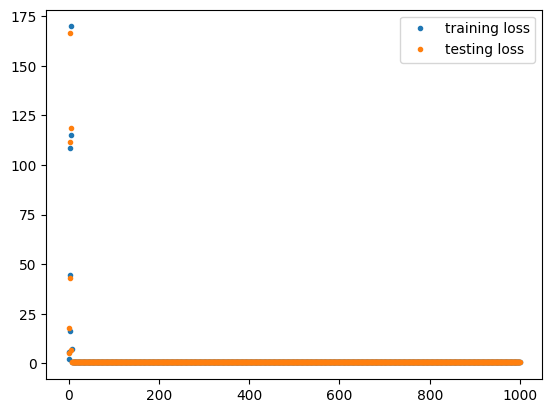

In [ ]:
#@title Main training loop

params_initial = initialize_params(layer_sizes, seed=1, scale=1e-1)
loss_fun = sigmoid_mse_loss
model = mlp_sigmoid
params, trajectory = gd_train(params_initial, loss_fun, model, data, step_size=1e-1, steps=1000)

plt.plot(trajectory['training_loss'], '.', label='training loss')
plt.plot(trajectory['testing_loss'],  '.', label='testing loss')
plt.legend()
plt.show()

The animation below visualizes how the predictions of the shallow Sigmoid network change during gradient descent. It is included to show how the model gradually adjusts its predictions during training and is separate from the final hyperparameter-tuning experiment.

In [ ]:
# Visualize the fitting process
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np
import matplotlib.pyplot as plt

def show_cartoon(data, trajectory):
    # cache numpy arrays once (avoid repeated .numpy() calls)
    tx = data['train_x'].detach().cpu().numpy()
    ty = data['train_y'].detach().cpu().numpy()
    preds = [p.detach().cpu().numpy() for p in trajectory['train_y_pred']]

    step = 10
    n_frames = max(1, min(len(preds) // step, 100))
    fig, ax = plt.subplots()
    sc_truth = ax.scatter(tx, ty, color='b', s=10, label='Ground Truth')
    sc_pred = ax.scatter(tx, preds[0], color='r', s=10, label='Training Prediction')

    ax.set_xlim(-1, 1)
    ax.set_ylim(-3, 0)
    ax.legend(loc='upper right')

    def animate(frame_num):
        idx = frame_num * step
        sc_pred.set_offsets(np.c_[tx, preds[idx].reshape(-1)])
        return (sc_pred,)

    anim = FuncAnimation(fig, animate, frames=n_frames, interval=60, blit=False)
    return fig, anim

fig, anim = show_cartoon(data, trajectory)

html = HTML(anim.to_jshtml())
plt.close(fig)
html

Sigmoid Baseline Experiment

In [ ]:
sigma = 1e-1
learning_rate = 1e-1
steps = 1000

In [ ]:
architecture = [1, 50, 50, 50, 1]

params_initial_sigmoid = initialize_params(
    architecture,
    seed=1,
    scale=sigma
)

params_sigmoid, trajectory_sigmoid = gd_train(
    params_initial_sigmoid,
    sigmoid_mse_loss,
    mlp_sigmoid,
    data,
    step_size=learning_rate,
    steps=steps
)

Step 0 | Training Loss:1.49063861 | Testing Loss:3.51488733
Step 100 | Training Loss:0.45683211 | Testing Loss:0.61423904
Step 200 | Training Loss:0.45681560 | Testing Loss:0.61426139
Step 300 | Training Loss:0.45679894 | Testing Loss:0.61428398
Step 400 | Training Loss:0.45678222 | Testing Loss:0.61430681
Step 500 | Training Loss:0.45676544 | Testing Loss:0.61432976
Step 600 | Training Loss:0.45674855 | Testing Loss:0.61435306
Step 700 | Training Loss:0.45673153 | Testing Loss:0.61437678
Step 800 | Training Loss:0.45671436 | Testing Loss:0.61440057
Step 900 | Training Loss:0.45669699 | Testing Loss:0.61442494


I first trained the Sigmoid network using $\sigma=0.1$, a learning rate of $0.1$, and 1000 steps as a baseline. The loss quickly plateaued, so I then tuned the initialization scale, learning rate, and number of training steps to improve performance.

In [ ]:
def run_sigmoid_experiment(sigma, learning_rate, steps):
    params_initial = initialize_params(
        architecture,
        seed=1,
        scale=sigma
    )

    params, trajectory = gd_train(
        params_initial,
        sigmoid_mse_loss,
        mlp_sigmoid,
        data,
        step_size=learning_rate,
        steps=steps
    )

    final_train = trajectory["training_loss"][-1]
    final_test = trajectory["testing_loss"][-1]

    return {
        "sigma": sigma,
        "learning_rate": learning_rate,
        "steps": steps,
        "params": params,
        "trajectory": trajectory,
        "train_loss": final_train,
        "test_loss": final_test
    }

In [ ]:
sigma_values = [0.1, 0.5, 1.0, 2.0, 5.0]
learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1]

results = []

for sigma in sigma_values:
    for lr in learning_rates:

        print(f"\nSigma = {sigma}, Learning Rate = {lr}")

        result = run_sigmoid_experiment(
            sigma=sigma,
            learning_rate=lr,
            steps=1000
        )

        results.append(result)

        print(
            "Final Train Loss:",
            result["train_loss"],
            "| Final Test Loss:",
            result["test_loss"]
        )


Sigma = 0.1, Learning Rate = 0.001
Step 0 | Training Loss:1.49063861 | Testing Loss:1.87014616
Step 100 | Training Loss:0.46022838 | Testing Loss:0.63306022
Step 200 | Training Loss:0.45692867 | Testing Loss:0.61501056
Step 300 | Training Loss:0.45691833 | Testing Loss:0.61416781
Step 400 | Training Loss:0.45691821 | Testing Loss:0.61412156
Step 500 | Training Loss:0.45691809 | Testing Loss:0.61411905
Step 600 | Training Loss:0.45691794 | Testing Loss:0.61411911
Step 700 | Training Loss:0.45691788 | Testing Loss:0.61411923
Step 800 | Training Loss:0.45691779 | Testing Loss:0.61411941
Step 900 | Training Loss:0.45691764 | Testing Loss:0.61411947
Final Train Loss: 0.45691752433776855 | Final Test Loss: 0.6141196489334106

Sigma = 0.1, Learning Rate = 0.005
Step 0 | Training Loss:1.49063861 | Testing Loss:1.62484241
Step 100 | Training Loss:0.45691809 | Testing Loss:0.61411899
Step 200 | Training Loss:0.45691752 | Testing Loss:0.61411965
Step 300 | Training Loss:0.45691708 | Testing Loss

In [ ]:
best_pair = min(
    results,
    key=lambda x: x["test_loss"]
)

print("\nBest combination:")
print("sigma =", best_pair["sigma"])
print("learning rate =", best_pair["learning_rate"])
print("training loss =", best_pair["train_loss"])
print("test loss =", best_pair["test_loss"])


Best combination:
sigma = 2.0
learning rate = 0.01
training loss = 0.0008399543585255742
test loss = 0.0017877600621432066


In [ ]:
step_values = [500, 1000, 2000, 5000]

step_results = []

for num_steps in step_values:

    result = run_sigmoid_experiment(
        sigma=best_pair["sigma"],
        learning_rate=best_pair["learning_rate"],
        steps=num_steps
    )

    step_results.append(result)

    print(
        f"Steps: {num_steps} | "
        f"Train Loss: {result['train_loss']:.8f} | "
        f"Test Loss: {result['test_loss']:.8f}"
    )

Step 0 | Training Loss:11.93822670 | Testing Loss:4.08077288
Step 100 | Training Loss:0.02654702 | Testing Loss:0.03860645
Step 200 | Training Loss:0.00986247 | Testing Loss:0.01696342
Step 300 | Training Loss:0.00439772 | Testing Loss:0.00892538
Step 400 | Training Loss:0.00245978 | Testing Loss:0.00601378
Steps: 500 | Train Loss: 0.03199678 | Test Loss: 0.02511153
Step 0 | Training Loss:11.93822670 | Testing Loss:4.08077288
Step 100 | Training Loss:0.02654702 | Testing Loss:0.03860645
Step 200 | Training Loss:0.00986247 | Testing Loss:0.01696342
Step 300 | Training Loss:0.00439772 | Testing Loss:0.00892538
Step 400 | Training Loss:0.00245978 | Testing Loss:0.00601378
Step 500 | Training Loss:0.03127147 | Testing Loss:0.04506776
Step 600 | Training Loss:0.00227833 | Testing Loss:0.00531362
Step 700 | Training Loss:0.00111963 | Testing Loss:0.00264795
Step 800 | Training Loss:0.00098428 | Testing Loss:0.00217434
Step 900 | Training Loss:0.00090246 | Testing Loss:0.00194729
Steps: 1000 

In [ ]:
best_result = min(
    step_results,
    key=lambda x: x["test_loss"]
)

print("\nBest Sigmoid Result")
print("sigma =", best_result["sigma"])
print("learning rate =", best_result["learning_rate"])
print("steps =", best_result["steps"])
print("training loss =", best_result["train_loss"])
print("test loss =", best_result["test_loss"])


Best Sigmoid Result
sigma = 2.0
learning rate = 0.01
steps = 5000
training loss = 0.000297101738397032
test loss = 0.0005347065743990242


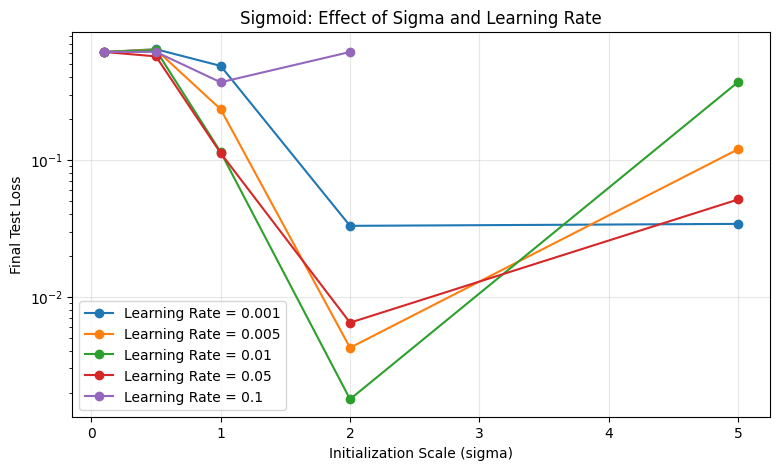

In [ ]:
plt.figure(figsize=(9, 5))

for lr in learning_rates:
    test_losses = []

    for sigma in sigma_values:
        result = next(
            r for r in results
            if r["sigma"] == sigma
            and r["learning_rate"] == lr
        )

        test_losses.append(result["test_loss"])

    plt.plot(
        sigma_values,
        test_losses,
        marker="o",
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Initialization Scale (sigma)")
plt.ylabel("Final Test Loss")
plt.title("Sigmoid: Effect of Sigma and Learning Rate")

plt.yscale("log")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

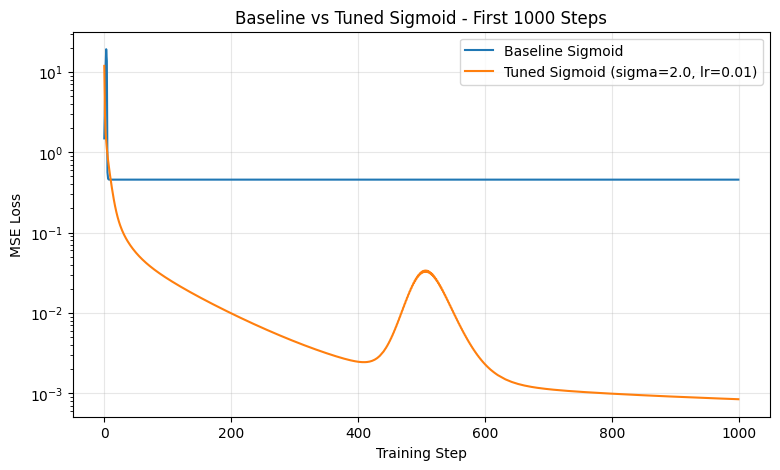

In [ ]:
plt.figure(figsize=(9, 5))

# Compare both over the same 1000 steps
plt.plot(
    trajectory_sigmoid["training_loss"],
    label="Baseline Sigmoid"
)

plt.plot(
    best_result["trajectory"]["training_loss"][:1000],
    label=(
        f"Tuned Sigmoid "
        f"(sigma={best_result['sigma']}, "
        f"lr={best_result['learning_rate']})"
    )
)

plt.xlabel("Training Step")
plt.ylabel("MSE Loss")
plt.title("Baseline vs Tuned Sigmoid - First 1000 Steps")

plt.yscale("log")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

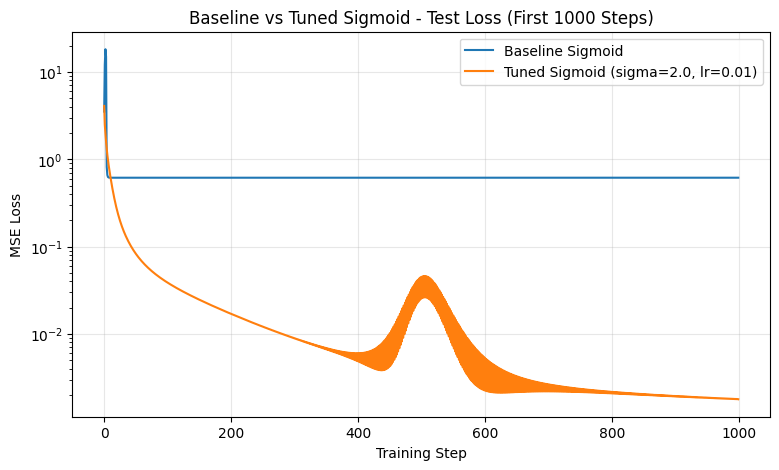

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    trajectory_sigmoid["testing_loss"],
    label="Baseline Sigmoid"
)

plt.plot(
    best_result["trajectory"]["testing_loss"][:1000],
    label=(
        f"Tuned Sigmoid "
        f"(sigma={best_result['sigma']}, "
        f"lr={best_result['learning_rate']})"
    )
)

plt.xlabel("Training Step")
plt.ylabel("MSE Loss")
plt.title("Baseline vs Tuned Sigmoid - Test Loss (First 1000 Steps)")

plt.yscale("log")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

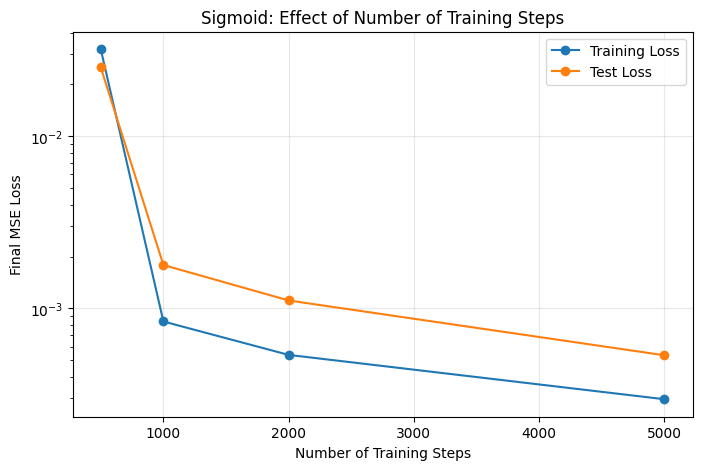

In [ ]:
steps_plot = [r["steps"] for r in step_results]
train_losses = [r["train_loss"] for r in step_results]
test_losses = [r["test_loss"] for r in step_results]

plt.figure(figsize=(8, 5))

plt.plot(
    steps_plot,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    steps_plot,
    test_losses,
    marker="o",
    label="Test Loss"
)

plt.xlabel("Number of Training Steps")
plt.ylabel("Final MSE Loss")
plt.title("Sigmoid: Effect of Number of Training Steps")

plt.yscale("log")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Sigmoid networks can be harder to train because the Sigmoid activation can cause vanishing gradients. When the input to Sigmoid becomes very positive or very negative, the function becomes almost flat, so its derivative becomes very small. During backpropagation, these small gradients are multiplied across multiple layers, causing the gradient to become even smaller as it reaches the earlier layers. As a result, the earlier layers receive very small parameter updates and learn slowly.

This behavior was visible in my experiment because the baseline Sigmoid network quickly reached a plateau and stopped improving. After adjusting the initialization scale, learning rate, and number of iterations, the network was able to train much more effectively.

### Best Results and Insights

My best Sigmoid result used:

- Initialization scale: $\sigma = 2.0$
- Learning rate: $0.01$
- Training iterations: $5000$

With these settings, the final training loss was approximately $0.000297$ and the test loss was approximately $0.000535$.

This was a large improvement over the baseline Sigmoid experiment. In the baseline, the training loss stayed around $0.4567$ and the test loss stayed around $0.6144$, showing that the network had mostly stopped improving.

One insight from the experiment is that Sigmoid was very sensitive to the initialization scale and learning rate. The original settings caused the network to plateau, but tuning both parameters together allowed the model to learn much more effectively. Increasing the number of iterations also improved performance. At 5000 iterations, the training loss reached about $0.000297$ and the test loss reached about $0.000535$.

Overall, the experiment showed that Sigmoid can be harder to train because of vanishing gradients, but careful initialization, a smaller learning rate, and more training iterations can greatly improve its performance.

# Huber Loss

### Question 1

After reading the Pytorch Huber loss documentation, I gathered that it looks at the difference between the prediction and the true value. If the difference is small, Huber loss treats it like squared error. If the difference is large, Huber loss stops squaring it and switches to a linear penalty. The delta value is the cutoff that decides what counts as "small" versus "large". So if,

```
delta = 1.0
```
then



```
|error| <= 1
→ use squared loss

|error| > 1
→ use linear loss
```







Then, reading the scikit-learn HuberRegressor documentation, it explains that Huber regression is robust to outliers because it uses squared loss for smaller residuals and absolute/linear loss for larger residuals, so outliers are not allowed to dominate the objective as strongly.

In comparison, mean squared error continues squaring large errors, so an outlier can contribute a much larger penalty and have a stronger influence on the model.

Lastly, by reading the scikit-learn plot_huber_vs_ridge, the HuberRegressor example also shows that models using squared loss can be pulled more strongly toward outliers, while Huber regression reduces their influence.

References:


1.   https://docs.pytorch.org/docs/main/generated/torch.nn.functional.huber_loss.html
2.   https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.HuberRegressor.html
3.   https://scikit-learn.org/stable/auto_examples/linear_model/plot_huber_vs_ridge.html








### Question 2

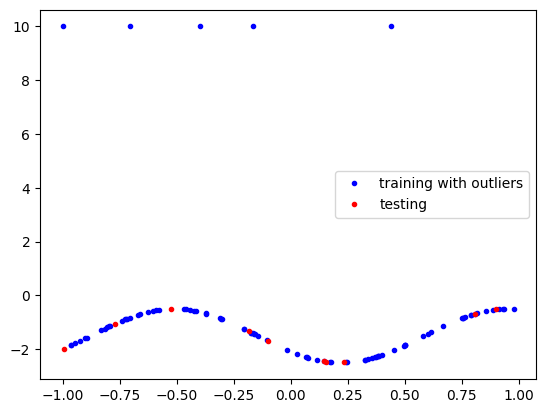

In [ ]:
#@title Add outliers to the training data

# Keep the original data unchanged
train_y_outlier = train_y.clone()

# Set the first five training labels to 10
train_y_outlier[:5] = 10

# Create a new dataset containing the outliers
data_outlier = {
    "train_x": train_x,
    "train_y": train_y_outlier,
    "test_x": test_x,
    "test_y": test_y
}

# Plot the modified dataset
plt.plot(
    data_outlier["train_x"].numpy(),
    data_outlier["train_y"].numpy(),
    ".b",
    label="training with outliers"
)

plt.plot(
    data_outlier["test_x"].numpy(),
    data_outlier["test_y"].numpy(),
    ".r",
    label="testing"
)

plt.legend()
plt.show()

In [ ]:
def huber_loss(params, x, y):
    pred = mlp(params, x)
    return F.huber_loss(pred, y, delta=1.0)

In [ ]:
#@title Train MSE vs Huber on data with outliers

architecture = [1, 50, 50, 50, 1]

params_initial = initialize_params(
    architecture,
    scale=0.1,
    seed=1
)

# Train with MSE
params_mse, trajectory_mse = gd_train(
    params_initial,
    mse_loss,
    mlp,
    data_outlier,
    step_size=0.1,
    steps=1000
)

# Train with Huber
params_huber, trajectory_huber = gd_train(
    params_initial,
    huber_loss,
    mlp,
    data_outlier,
    step_size=0.1,
    steps=1000
)

Step 0 | Training Loss:7.59540939 | Testing Loss:2.02229166
Step 100 | Training Loss:6.80048609 | Testing Loss:1.11779809
Step 200 | Training Loss:6.63141012 | Testing Loss:0.98094404
Step 300 | Training Loss:6.61508703 | Testing Loss:0.63526076
Step 400 | Training Loss:6.56816149 | Testing Loss:0.78302705
Step 500 | Training Loss:6.52051401 | Testing Loss:0.60385406
Step 600 | Training Loss:6.48536110 | Testing Loss:0.84271592
Step 700 | Training Loss:6.51763773 | Testing Loss:0.83382338
Step 800 | Training Loss:6.51737595 | Testing Loss:0.74282444
Step 900 | Training Loss:6.57574940 | Testing Loss:0.38220534
Step 0 | Training Loss:1.27549505 | Testing Loss:0.84239805
Step 100 | Training Loss:0.80628449 | Testing Loss:0.31187505
Step 200 | Training Loss:0.77982831 | Testing Loss:0.28724271
Step 300 | Training Loss:0.70968437 | Testing Loss:0.17263639
Step 400 | Training Loss:0.64893150 | Testing Loss:0.09567522
Step 500 | Training Loss:0.62779427 | Testing Loss:0.06352904
Step 600 | T

In [ ]:
with torch.no_grad():

    mse_test = mse_loss(
        params_mse,
        test_x,
        test_y
    ).item()

    huber_test = mse_loss(
        params_huber,
        test_x,
        test_y
    ).item()

print("MSE-trained model test MSE:", mse_test)
print("Huber-trained model test MSE:", huber_test)

MSE-trained model test MSE: 0.7916514873504639
Huber-trained model test MSE: 0.04615316912531853


After introducing outliers by setting the first five training labels to 10, I trained the same MLP using MSE loss and Huber loss. Both models used the same architecture, initialization, learning rate, and number of training iterations.

When evaluated using MSE on the unchanged test set, the model trained with MSE had a test MSE of approximately $0.792$, while the model trained with Huber loss had a much lower test MSE of approximately $0.046$.

These results show that the MSE-trained model was much more strongly affected by the outliers. Because MSE squares large errors, the outliers had a large influence during training. Huber loss reduced the influence of these large errors by switching to a linear penalty, allowing the model to better fit the underlying pattern of the non-outlier data.